# Task 3: Explore the data

Using exploratory data analysis to better understand the dataset commutes_clean.csv and the questions we are investigating:
1. What does the majority of people use to commute?
2. What time windows have the highest volume of commuters?
3. Are there specific days where commute times spike?
4. Which data points (weather, distance, transport mode) show the most interaction with each other?
5. How many observations did we lose or gain by switching to the new form format?


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
commute_data = pd.read_csv("data/processed/commutes_clean.csv")


In [3]:
commute_data.shape

(222, 15)

In [4]:
commute_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 222 entries, 0 to 221
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   respondent_id           222 non-null    str    
 1   date                    222 non-null    str    
 2   day_of_week             222 non-null    str    
 3   depart_time             222 non-null    str    
 4   arrival_time            222 non-null    str    
 5   duration_minutes        222 non-null    int64  
 6   distance_miles          222 non-null    float64
 7   mode_of_transportation  222 non-null    str    
 8   weather                 222 non-null    str    
 9   location                222 non-null    str    
 10  location_clean          222 non-null    str    
 11  location_region         222 non-null    str    
 12  is_rainy                222 non-null    bool   
 13  near_uic                222 non-null    bool   
 14  duration_bucket         222 non-null    str    
dtype

In [7]:
commute_data.head()

,respondent_id,date,day_of_week,depart_time,arrival_time,duration_minutes,distance_miles,mode_of_transportation,weather,location,location_clean,location_region,is_rainy,near_uic,duration_bucket
0,R1,2026-10-15,Thursday,07:33:00,08:55:00,82,27.0,Car,Cloudy,Carol Stream,Carol Stream,Suburb,False,False,75-90
1,R2,2026-10-08,Thursday,11:15:00,13:30:00,135,41.0,Train,Sunny,Algonquin,Algonquin,Suburb,False,False,90+
2,R3,2026-10-13,Tuesday,08:30:00,09:45:00,75,13.0,Car,Sunny,Belmont Cragin,Belmont Cragin,Chicago,False,False,75-90
3,R4,2026-10-15,Thursday,09:30:00,10:05:00,35,13.0,Car,Cloudy,Belmont Cragin,Belmont Cragin,Chicago,False,False,30-45
4,R5,2026-10-12,Monday,07:00:00,07:45:00,45,16.0,Car,Sunny,Franklin Park,Franklin Park,Suburb,False,False,45-60


In [9]:
commute_data["mode_of_transportation"].head()

0      Car
1    Train
2      Car
3      Car
4      Car
Name: mode_of_transportation, dtype: str

In [10]:
commute_data["mode_of_transportation"].value_counts()

mode_of_transportation
Train      92
Car        76
Walk       32
Bus        15
Bike        5
Carpool     2
Name: count, dtype: int64

# 1. What does the majority of people use to commute?

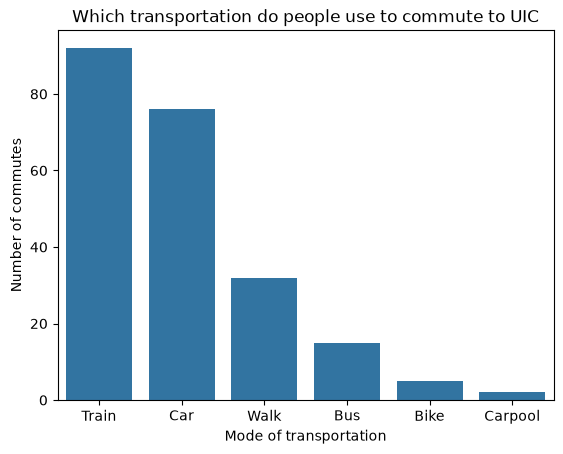

In [22]:
transportation_order = commute_data["mode_of_transportation"].value_counts().index
ax = sns.countplot(commute_data, x = "mode_of_transportation", order = transportation_order, legend = True)
ax.set_xlabel("Mode of transportation")
ax.set_ylabel("Number of commutes")
ax.set_title("Which transportation do people use to commute to UIC")
plt.show()


In [23]:
commute_data["location_region"].value_counts()

location_region
Suburb     135
Chicago     76
Unknown     11
Name: count, dtype: int64

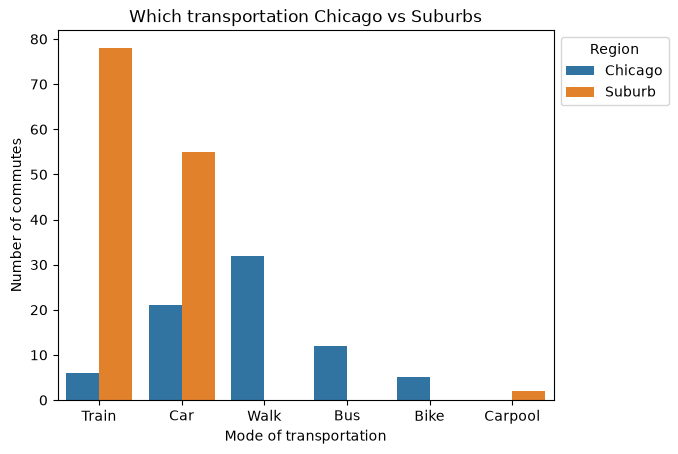

In [29]:
region = ["Chicago", "Suburb"]
ax = sns.countplot(commute_data, x = "mode_of_transportation", order = transportation_order, hue = "location_region", hue_order = region, legend = True)
ax.set_xlabel("Mode of transportation")
ax.set_ylabel("Number of commutes")
ax.set_title("Which transportation Chicago vs Suburbs")
sns.move_legend(ax, "upper left", bbox_to_anchor = (1,1), title = "Region")
plt.show()

* Looking at the graph we can concluded that Train is the transportation mode that's used by majority of our respondents
* It is important to note that there are 135 commutes from the suburbs and 76 from Chicago which as shown in the second graph makes some comparisons misleading
* Looking at the second graph we can see that there are almost 80 commutes from suburbs with train and less then 10 are from people that commute from Chicago, which we were suprised about since Chicago has many train lines and blue line is right next to UIC
* Since there are more people coming from suburbs we can cocnlude that that's one of the reasons why train trasnsportation is so popular
* For people commuting from Chicago we can see that walking, car and bus are more popular transportation modes but their number is not as hign as the train, since there are less people commuting from Chicago that completed the form
* We can also see that only 5 people from Chicago use bike as transportation and only few people from suburbs use carpool as transportation, which might not be very useful in our later reseach

# 2. What time windows have the highest volume of commuters?

In [32]:
commute_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 222 entries, 0 to 221
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   respondent_id           222 non-null    str    
 1   date                    222 non-null    str    
 2   day_of_week             222 non-null    str    
 3   depart_time             222 non-null    str    
 4   arrival_time            222 non-null    str    
 5   duration_minutes        222 non-null    int64  
 6   distance_miles          222 non-null    float64
 7   mode_of_transportation  222 non-null    str    
 8   weather                 222 non-null    str    
 9   location                222 non-null    str    
 10  location_clean          222 non-null    str    
 11  location_region         222 non-null    str    
 12  is_rainy                222 non-null    bool   
 13  near_uic                222 non-null    bool   
 14  duration_bucket         222 non-null    str    
dtype

In [69]:
commute_data["depart_time"].value_counts()

depart_time
09:30:00    8
07:46:00    8
09:50:00    5
09:00:00    4
10:30:00    4
           ..
10:08:00    1
10:06:00    1
06:56:00    1
08:21:00    1
08:18:00    1
Name: count, Length: 145, dtype: int64

In [73]:
commute_data["arrival_time"].value_counts()

arrival_time
09:00:00    51
08:00:00    42
10:00:00    35
11:00:00    32
12:00:00    17
07:00:00    12
14:00:00     6
10:20:00     3
08:55:00     1
13:30:00     1
09:45:00     1
10:05:00     1
07:45:00     1
08:40:00     1
07:50:00     1
09:06:00     1
10:30:00     1
10:34:00     1
08:22:00     1
10:49:00     1
11:19:00     1
09:48:00     1
10:02:00     1
08:45:00     1
00:30:00     1
08:50:00     1
08:42:00     1
10:24:00     1
10:45:00     1
10:32:00     1
10:15:00     1
23:50:00     1
Name: count, dtype: int64

In [74]:
commute_data["arrival_hour"] = commute_data["arrival_time"].str[0:2]
commute_data["arrival_hour"] = commute_data["arrival_hour"].astype(int)
commute_data["arrival_hour"].value_counts()

arrival_hour
9     54
8     48
10    47
11    33
12    17
7     14
14     6
13     1
0      1
23     1
Name: count, dtype: int64

In [75]:
commute_data["depart_hour"] = commute_data["depart_time"].str[0:2]
commute_data["depart_hour"] = commute_data["depart_hour"].astype(int)
commute_data["depart_hour"].value_counts()

depart_hour
9     53
7     45
8     41
10    32
6     26
11     9
5      9
13     6
23     1
Name: count, dtype: int64

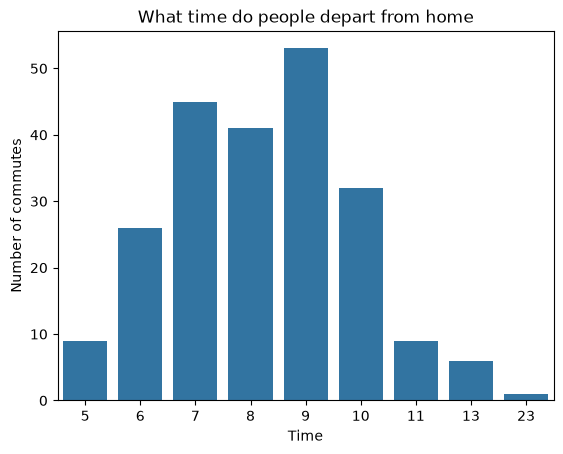

In [76]:
ax = sns.countplot(commute_data, x = "depart_hour")
ax.set_xlabel("Time")
ax.set_ylabel("Number of commutes")
ax.set_title("What time do people depart from home")
plt.show()

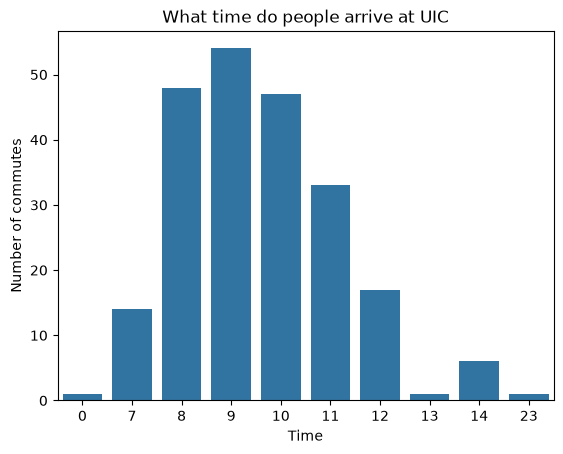

In [77]:
ax = sns.countplot(commute_data, x = "arrival_hour")
ax.set_xlabel("Time")
ax.set_ylabel("Number of commutes")
ax.set_title("What time do people arrive at UIC")
plt.show()

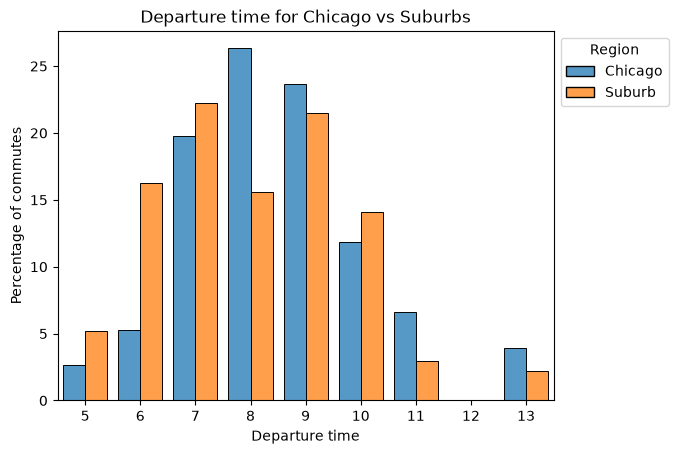

In [78]:
region = ["Chicago", "Suburb"]
ax = sns.histplot(commute_data, x = "depart_hour", hue = "location_region", hue_order = region, legend = True, stat = "percent", multiple = "dodge", shrink = 0.8, common_norm = False, discrete = True)
ax.set_xlabel("Departure time")
ax.set_ylabel("Percentage of commutes")
ax.set_xticks(range(5,14))
ax.set_xlim(4.5, 13.5)
ax.set_title("Departure time for Chicago vs Suburbs")
sns.move_legend(ax, "upper left", bbox_to_anchor = (1,1), title = "Region")
plt.show()

* Looking at the first graph that shows how many people depart from their home during specific hour of the day we can see that the higest number of commutes happens around 9am and they range from 5am to 1pm
* Looking at the second graph that shows how many people arrive on campus during specific hour of the day we can see that the higest number of arrivals happens around 9am as well and they range from 7am to 2 pm
* Also, we noticed one inconsistency, one person that shows up for darrival at 23:50 and 00:30, is probably a mistake when someone was filling the form and they wrote pm instead of am
* Looking at the third graph we can see the relationship and time of departure between people who live in Chicago and people who live in suburbs. The data was normalized because the first time we made the graph, since there are a lot more people commuting from Saburb it seemed as they have the greatest number of commute for each hour. Right now we can see that people who live in Chicago have later departure time than people who live in suburbs(peak is around 8 and 9 am while for suburbs is around 7 am and 9 am and there is greater number of people that departs around 5 and 6 am)

# 3. Are there specific days where commute times spike?